In [1]:
import socket

for host in ["pypi.org", "physionet.org"]:
    print(host, "→", socket.gethostbyname(host))

pypi.org → 151.101.0.223
physionet.org → 18.25.8.254


In [2]:
%pip install -q wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import wfdb

record = wfdb.rdrecord(
    "00001_lr",
    pn_dir="ptb-xl/1.0.3/records100/00000",
)

signal = record.p_signal

print("数据形状：", signal.shape)
print("采样率：", record.fs, "Hz")
print("导联名称：", record.sig_name)

数据形状： (1000, 12)
采样率： 100 Hz
导联名称： ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


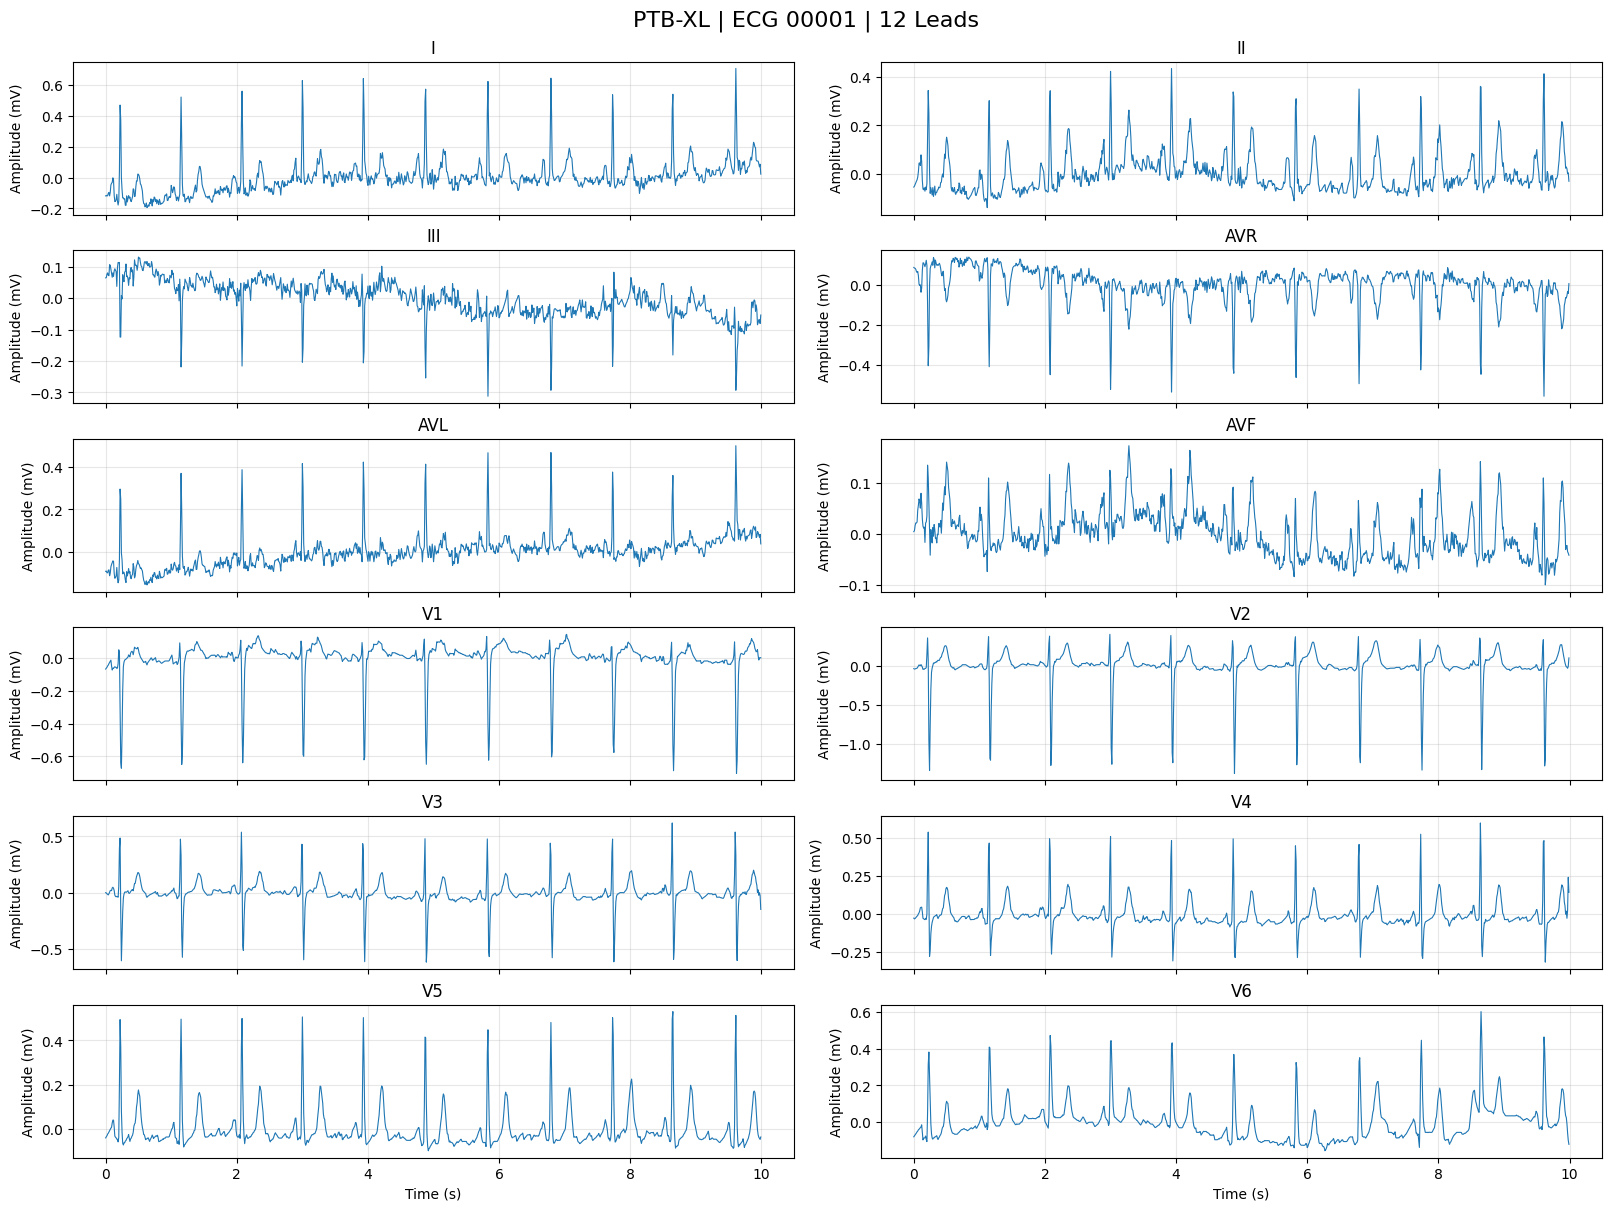

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 将采样点转换为秒
time = np.arange(signal.shape[0]) / record.fs

# 每个导联画一张子图
fig, axes = plt.subplots(
    6, 2,
    figsize=(16, 12),
    sharex=True,
    constrained_layout=True,
)

for i, ax in enumerate(axes.flat):
    ax.plot(time, signal[:, i], linewidth=0.8)
    ax.set_title(record.sig_name[i])
    ax.set_ylabel(f"Amplitude ({record.units[i]})")
    ax.grid(alpha=0.3)

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle("PTB-XL | ECG 00001 | 12 Leads", fontsize=16)

# 保存图片，方便后续放进项目报告
fig.savefig(
    "/kaggle/working/ecg_00001.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [5]:
import pandas as pd
import ast

base_url = "https://physionet.org/files/ptb-xl/1.0.3/"

# 读取记录信息和标签含义
metadata = pd.read_csv(
    base_url + "ptbxl_database.csv",
    index_col="ecg_id",
)

statements = pd.read_csv(
    base_url + "scp_statements.csv",
    index_col=0,
)

# 刚才画出的记录是 ECG 00001
sample = metadata.loc[1]
codes = ast.literal_eval(sample["scp_codes"])

print("记录编号：", sample.name)
print("波形路径：", sample["filename_lr"])
print("原始标签：", codes)

# 展示每个标注的含义与诊断大类
label_table = statements.loc[
    list(codes),
    ["description", "diagnostic", "diagnostic_class"],
].copy()

label_table.columns = ["标签含义", "是否为诊断标签", "诊断大类"]
display(label_table)

记录编号： 1
波形路径： records100/00000/00001_lr
原始标签： {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}


,标签含义,是否为诊断标签,诊断大类
NORM,normal ECG,1.0,NORM
LVOLT,low QRS voltages in the frontal and horizontal...,NaN,NaN
SR,sinus rhythm,NaN,NaN


In [6]:
import numpy as np

classes = ["NORM", "MI", "STTC", "CD", "HYP"]

# 只建立“诊断标注代码 → 诊断大类”的映射
diagnostic_map = (
    statements.loc[statements["diagnostic"].eq(1), "diagnostic_class"]
    .dropna()
    .to_dict()
)

def get_diagnostic_classes(scp_codes):
    codes = ast.literal_eval(scp_codes)
    return sorted({
        diagnostic_map[code]
        for code in codes
        if code in diagnostic_map
    })

# 每条记录可能对应多个诊断大类
metadata["diagnostic_classes"] = metadata["scp_codes"].apply(
    get_diagnostic_classes
)

# 没有诊断大类的记录不作为本任务的训练样本
data = metadata[
    metadata["diagnostic_classes"].map(len) > 0
].copy()

# 每一行对应一条记录，每一列对应一个诊断大类
y = np.array([
    [int(cls in labels) for cls in classes]
    for labels in data["diagnostic_classes"]
], dtype=np.float32)

print("类别顺序：", classes)
print("标签矩阵形状：", y.shape)

sample_position = data.index.get_loc(1)
print("记录 1 的诊断大类：", data.loc[1, "diagnostic_classes"])
print("记录 1 的标签向量：", y[sample_position])

display(pd.DataFrame({
    "诊断大类": classes,
    "阳性记录数": y.sum(axis=0).astype(int),
}))

类别顺序： ['NORM', 'MI', 'STTC', 'CD', 'HYP']
标签矩阵形状： (21388, 5)
记录 1 的诊断大类： ['NORM']
记录 1 的标签向量： [1. 0. 0. 0. 0.]


,诊断大类,阳性记录数
0,NORM,9514
1,MI,5469
2,STTC,5235
3,CD,4898
4,HYP,2649


In [7]:
# 按官方折编号划分，保持 data 与 y 的行顺序一致
train_mask = data["strat_fold"].isin(range(1, 9)).to_numpy()
val_mask = data["strat_fold"].eq(9).to_numpy()
test_mask = data["strat_fold"].eq(10).to_numpy()

train_data = data.loc[train_mask].copy()
val_data = data.loc[val_mask].copy()
test_data = data.loc[test_mask].copy()

y_train = y[train_mask]
y_val = y[val_mask]
y_test = y[test_mask]

# 检查每条记录恰好属于一个集合
assert (
    train_mask.astype(int)
    + val_mask.astype(int)
    + test_mask.astype(int)
    == 1
).all()

# 检查不同集合没有同一位患者
train_patients = set(train_data["patient_id"])
val_patients = set(val_data["patient_id"])
test_patients = set(test_data["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

summary = pd.DataFrame({
    "集合": ["训练集", "验证集", "测试集"],
    "记录数": [len(train_data), len(val_data), len(test_data)],
    "患者数": [
        len(train_patients),
        len(val_patients),
        len(test_patients),
    ],
})

display(summary)

class_counts = pd.DataFrame(
    {
        "训练集": y_train.sum(axis=0).astype(int),
        "验证集": y_val.sum(axis=0).astype(int),
        "测试集": y_test.sum(axis=0).astype(int),
    },
    index=classes,
)

display(class_counts)
print("检查通过：三个集合之间没有患者重叠。")

,集合,记录数,患者数
0,训练集,17084,14823
1,验证集,2146,1917
2,测试集,2158,1877


,训练集,验证集,测试集
NORM,7596,955,963
MI,4379,540,550
STTC,4186,528,521
CD,3907,495,496
HYP,2119,268,262


检查通过：三个集合之间没有患者重叠。


In [8]:
from pathlib import Path

input_root = Path("/kaggle/input")

# 查找波形目录和元数据
for path in input_root.rglob("records100"):
    if path.is_dir():
        print("100 Hz 波形目录：", path)
        print("波形文件数量：", sum(1 for _ in path.rglob("*.dat")))

for path in input_root.rglob("ptbxl_database.csv"):
    print("元数据路径：", path)

100 Hz 波形目录： /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records100
波形文件数量： 21837
元数据路径： /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/ptbxl_database.csv


In [9]:
from pathlib import Path
import numpy as np
import wfdb

# 自动找到镜像数据根目录
folders = [
    p for p in Path("/kaggle/input").rglob("records100")
    if p.is_dir()
]
assert len(folders) == 1, f"找到 {len(folders)} 个目录，需要确认"
data_root = folders[0].parent

# 检查现有 1.0.3 标签所对应的文件是否齐全
missing = []

for ecg_id, row in data.iterrows():
    base = data_root / row["filename_lr"]
    if not (
        base.with_suffix(".hea").is_file()
        and base.with_suffix(".dat").is_file()
    ):
        missing.append(ecg_id)

print("数据根目录：", data_root)
print("待使用记录数：", len(data))
print("缺失记录数：", len(missing))
assert not missing, f"缺失记录示例：{missing[:10]}"

# 从 Kaggle 挂载目录读取第一条波形
local_record = wfdb.rdrecord(
    str(data_root / data.loc[1, "filename_lr"])
)

print("本地波形形状：", local_record.p_signal.shape)
print("采样率：", local_record.fs)
print("导联顺序：", local_record.sig_name)

assert local_record.p_signal.shape == (1000, 12)
assert local_record.fs == 100
assert np.isfinite(local_record.p_signal).all()

# 与前面从官方 1.0.3 读取的同一条记录比较
assert local_record.sig_name == record.sig_name
np.testing.assert_allclose(
    local_record.p_signal,
    record.p_signal,
    rtol=0,
    atol=1e-6,
)

print("检查通过：文件齐全，第一条波形与官方样本一致。")

数据根目录： /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
待使用记录数： 21388
缺失记录数： 0
本地波形形状： (1000, 12)
采样率： 100
导联顺序： ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
检查通过：文件齐全，第一条波形与官方样本一致。


In [10]:
from tqdm.auto import tqdm
import numpy as np
import wfdb

# 约占 1 GB 内存，采用 float32
X = np.empty((len(data), 12, 1000), dtype=np.float32)
expected_leads = local_record.sig_name

for i, (ecg_id, row) in enumerate(
    tqdm(data.iterrows(), total=len(data), desc="读取心电图")
):
    rec = wfdb.rdrecord(str(data_root / row["filename_lr"]))

    # 检查每条记录，发现异常时停止并显示记录编号
    assert rec.fs == 100, f"采样率异常：{ecg_id}"
    assert rec.sig_name == expected_leads, f"导联顺序异常：{ecg_id}"
    assert rec.p_signal.shape == (1000, 12), f"形状异常：{ecg_id}"
    assert np.isfinite(rec.p_signal).all(), f"存在无效值：{ecg_id}"

    # 转为 PyTorch 常用的“导联 × 时间点”格式
    X[i] = rec.p_signal.T.astype(np.float32)

print("波形数组：", X.shape)
print("标签数组：", y.shape)
print(f"波形占用内存：{X.nbytes / 1024**3:.2f} GiB")

assert len(X) == len(y)
print("批量读取完成，波形与标签行顺序一致。")

读取心电图:   0%|          | 0/21388 [00:00<?, ?it/s]

波形数组： (21388, 12, 1000)
标签数组： (21388, 5)
波形占用内存：0.96 GiB
批量读取完成，波形与标签行顺序一致。


In [11]:
from pathlib import Path
import numpy as np

# 只用训练集计算每个导联的均值和标准差
train_indices = np.flatnonzero(train_mask)

channel_sum = np.zeros(12, dtype=np.float64)
channel_sq_sum = np.zeros(12, dtype=np.float64)
point_count = 0

# 分批计算，控制内存占用
for start in range(0, len(train_indices), 256):
    batch = X[train_indices[start:start + 256]].astype(np.float64)

    channel_sum += batch.sum(axis=(0, 2))
    channel_sq_sum += np.square(batch).sum(axis=(0, 2))
    point_count += batch.shape[0] * batch.shape[2]

mean = (channel_sum / point_count).reshape(1, 12, 1)
variance = channel_sq_sum / point_count - mean.reshape(12) ** 2
std = np.sqrt(np.maximum(variance, 0)).reshape(1, 12, 1)

assert np.isfinite(mean).all()
assert np.isfinite(std).all()
assert (std > 0).all(), "存在标准差为零的导联"

mean = mean.astype(np.float32)
std = std.astype(np.float32)

# 三个集合使用同一套训练集参数，分批原地标准化
for start in range(0, len(X), 256):
    X[start:start + 256] -= mean
    X[start:start + 256] /= std

assert np.isfinite(X).all()

# 保存数组、划分、类别顺序和标准化参数
output_dir = Path("/kaggle/working/ecg_prepared")
output_dir.mkdir(exist_ok=True)

np.save(output_dir / "X.npy", X)
np.save(output_dir / "y.npy", y)

np.savez(
    output_dir / "metadata.npz",
    ecg_ids=data.index.to_numpy(),
    patient_ids=data["patient_id"].to_numpy(),
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
    classes=np.array(classes),
    leads=np.array(expected_leads),
    mean=mean,
    std=std,
)

print("标准化及文件保存完成")
print("保存目录：", output_dir)
print("X：", X.shape)
print("y：", y.shape)

标准化及文件保存完成
保存目录： /kaggle/working/ecg_prepared
X： (21388, 12, 1000)
y： (21388, 5)
